# 9. Is the model looking at the disease, or at the camera?

In DeepDRiD, the larger photos are far more often referable than the smaller ones. Image size may point to a different camera or clinic, although the dataset doesn't confirm that.

A model could therefore score well partly by recognising the type of photo. That wouldn't help in a Kenyan village, so we check for it here.

It compares every model it finds in `results`, so run it again after adding the neural networks from notebook 8.

In [1]:
%pip install -q numpy pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path

# Finds the project folder wherever this notebook is opened from.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "DeepDRiD").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find the AfriEyeSamsung project folder. Open this notebook from inside it.")
PROCESSED, RESULTS, MODELS = ROOT / "data" / "processed", ROOT / "results", ROOT / "models"
print("Project folder:", ROOT)

Project folder: c:\Users\Administrator\Desktop\AfriEyeSamsung


In [3]:
import json

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_auc_score

metrics = {f.name.replace("_metrics.json", ""): json.loads(f.read_text()) for f in sorted(RESULTS.glob("*_metrics.json"))}
predictions = {slug: pd.read_csv(RESULTS / f"{slug}_predictions.csv") for slug in metrics}
labels = pd.read_csv(PROCESSED / "clean_labels.csv")
labels["image_size"] = labels.width.astype(int).astype(str) + " x " + labels.height.astype(int).astype(str)
for slug in predictions:
    predictions[slug] = predictions[slug].merge(labels[["image_id", "image_size"]], on="image_id", validate="one_to_one")
print("Models found:", ", ".join(m["model"] for m in metrics.values()))
print("Not run yet:", ", ".join(s for s in ["xgboost", "mobilenet_v3", "efficientnet_b0", "convnext_tiny"] if s not in metrics) or "none")

Models found: ConvNeXt-Tiny, EfficientNet-B0, Linear regression, Logistic regression, MobileNetV3, Random forest, Small CNN, XGBoost
Not run yet: none


In [4]:
import matplotlib.pyplot as plt

BLUE, TEAL, ORANGE, PURPLE, GREY = "#1F4E9E", "#00948F", "#C4581F", "#7A3E9D", "#8A94A6"
INK, MUTED, GRID = "#1B2433", "#566173", "#E3E7F0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.edgecolor": "#AEB6C5", "axes.labelcolor": MUTED, "axes.titlecolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
    "legend.frameon": False,
})

## Check 1: how strong is the difference?

If image size alone gives a high AUC, then a model can look good without seeing any disease.

In [5]:
scored = labels[labels.split.isin(["val", "test"])]
common = labels.image_size.value_counts().head(2).index.tolist()
summary = labels[labels.image_size.isin(common)].groupby(["split", "image_size"]).referable.agg(Photos="count", Referable="mean").reset_index()
summary["Referable"] = (summary.Referable * 100).round(1)
print(summary.to_string(index=False))
print("Photos with other sizes:", int((~labels.image_size.isin(common)).sum()))

known = labels[labels.image_size.isin(common)]
larger = (known.image_size == sorted(common)[-1]).astype(int)
size_auc = {s: roc_auc_score(known.referable[known.split == s], larger[known.split == s]) for s in ("train", "val", "test")}
print("AUC from image size alone, with no photo content:", {k: round(v, 3) for k, v in size_auc.items()})

split  image_size  Photos  Referable
 test 1736 x 1824     262       25.2
 test 1976 x 1984     132       72.7
train 1736 x 1824     744       27.4
train 1976 x 1984     420       72.9
  val 1736 x 1824     288       33.3
  val 1976 x 1984     108       77.8
Photos with other sizes: 46
AUC from image size alone, with no photo content: {'train': 0.713, 'val': 0.678, 'test': 0.719}


## Check 2: AUC inside each image size

Comparing photos of the same size removes the shortcut. A big fall means part of the overall score came from photo type, not disease.

The range is a 95% interval that resamples whole patients. With few patients, these ranges are wide.

In [6]:
def patient_ci(y, score, patients, repeats=500, seed=0):
    rng = np.random.default_rng(seed)
    y, score, patients = np.asarray(y), np.asarray(score), np.asarray(patients)
    ids = np.unique(patients)
    where = {p: np.where(patients == p)[0] for p in ids}
    results = []
    for _ in range(repeats):
        take = np.concatenate([where[p] for p in rng.choice(ids, len(ids))])
        if 0 < y[take].sum() < len(take):
            results.append(roc_auc_score(y[take], score[take]))
    return float(np.percentile(results, 2.5)), float(np.percentile(results, 97.5))


rows = []
for slug, p in predictions.items():
    for split in ("val", "test"):
        part = p[p.split == split]
        overall = roc_auc_score(part.referable, part.score)
        for size, g in part[part.image_size.isin(common)].groupby("image_size"):
            low, high = patient_ci(g.referable, g.score, g.patient_id)
            rows.append({"slug": slug, "Model": metrics[slug]["model"], "Split": split, "Image size": size, "Photos": len(g), "% referable": g.referable.mean() * 100,
                         "Overall AUC": overall, "AUC in this size": roc_auc_score(g.referable, g.score), "Low": low, "High": high})
within = pd.DataFrame(rows)
order = within[within.Split == "val"].groupby("Model")["Overall AUC"].first().sort_values(ascending=False).index.tolist()
view = within[within.Split == "test"].drop(columns=["slug", "Split"]).set_index("Model").loc[order].reset_index()
print(view.to_string(index=False, formatters={"% referable": "{:.0f}".format, "Overall AUC": "{:.3f}".format, "AUC in this size": "{:.3f}".format, "Low": "{:.2f}".format, "High": "{:.2f}".format}))

              Model  Image size  Photos % referable Overall AUC AUC in this size  Low High
      ConvNeXt-Tiny 1736 x 1824     262          25       0.978            0.981 0.95 1.00
      ConvNeXt-Tiny 1976 x 1984     132          73       0.978            0.927 0.87 0.97
        MobileNetV3 1736 x 1824     262          25       0.972            0.979 0.95 1.00
        MobileNetV3 1976 x 1984     132          73       0.972            0.906 0.83 0.96
    EfficientNet-B0 1736 x 1824     262          25       0.969            0.975 0.94 1.00
    EfficientNet-B0 1976 x 1984     132          73       0.969            0.889 0.81 0.94
          Small CNN 1736 x 1824     262          25       0.943            0.950 0.90 0.99
          Small CNN 1976 x 1984     132          73       0.943            0.813 0.70 0.91
Logistic regression 1736 x 1824     262          25       0.899            0.915 0.83 0.97
Logistic regression 1976 x 1984     132          73       0.899            0.677 0.55 0.79

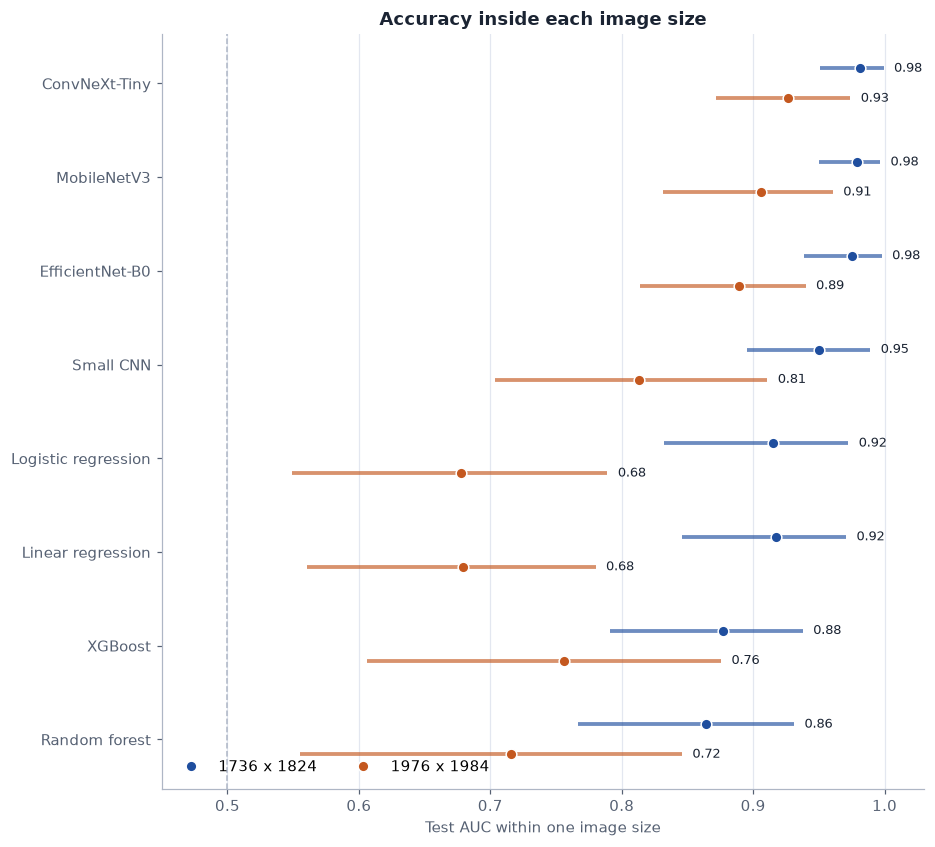

In [7]:
sizes = sorted(common)
fig, ax = plt.subplots(figsize=(8.6, max(3, .85 * len(order) + 1)))
ys = np.arange(len(order))[::-1]
for offset, size, color in zip((.16, -.16), sizes, (BLUE, ORANGE)):
    g = within[(within.Split == "test") & (within["Image size"] == size)].set_index("Model").loc[order]
    ax.hlines(ys + offset, g.Low, g.High, color=color, linewidth=2.5, alpha=.65)
    ax.plot(g["AUC in this size"], ys + offset, "o", color=color, markersize=7, markeredgecolor="white", label=size)
    for y, v, h in zip(ys, g["AUC in this size"], g.High):
        ax.text(h + .008, y + offset, f"{v:.2f}", va="center", fontsize=8.5, color=INK)
ax.axvline(.5, color="#AEB6C5", linestyle="--", linewidth=1)
ax.set_yticks(ys, order); ax.set_xlim(.45, 1.03); ax.set_xlabel("Test AUC within one image size"); ax.set_title("Accuracy inside each image size"); ax.grid(axis="y", visible=False); ax.legend(ncols=2, loc="lower left")
fig.tight_layout(); plt.show()

## Check 3: does the score give away the photo type?

We only use **non-referable** photos here, so disease can't explain the result. A value near 0.5 means the score doesn't depend on image size. A value near 1 means the model scores one photo type much higher, even when both are not referable.

In [8]:
leak = []
for slug, p in predictions.items():
    part = p[(p.split == "test") & (p.referable == 0) & p.image_size.isin(common)]
    leak.append({"Model": metrics[slug]["model"], "Photos": len(part), "Score separates image size (AUC)": roc_auc_score(part.image_size == sizes[-1], part.score)})
leak = pd.DataFrame(leak).set_index("Model").loc[order].reset_index()
print(leak.to_string(index=False, formatters={"Score separates image size (AUC)": "{:.3f}".format}))

              Model  Photos Score separates image size (AUC)
      ConvNeXt-Tiny     232                            0.858
        MobileNetV3     232                            0.948
    EfficientNet-B0     232                            0.915
          Small CNN     232                            0.903
Logistic regression     232                            0.967
  Linear regression     232                            0.966
            XGBoost     232                            0.898
      Random forest     232                            0.898


## Check 4: does the same cut-off work on both sizes?

The app uses one cut-off for every photo. If sensitivity or specificity differs a lot between sizes, that cut-off may behave differently on a new camera too.

In [9]:
def rates(y, score, threshold):
    tn, fp, fn, tp = confusion_matrix(y, np.asarray(score) >= threshold, labels=[0, 1]).ravel()
    return tp / max(1, tp + fn), tn / max(1, tn + fp)


cutoff = []
for slug, p in predictions.items():
    for size, g in p[(p.split == "test") & p.image_size.isin(common)].groupby("image_size"):
        sens, spec = rates(g.referable, g.score, metrics[slug]["threshold"])
        cutoff.append({"Model": metrics[slug]["model"], "Image size": size, "Sensitivity": sens, "Specificity": spec})
cutoff = pd.DataFrame(cutoff).set_index("Model").loc[order].reset_index()
print(cutoff.to_string(index=False, formatters={"Sensitivity": "{:.1%}".format, "Specificity": "{:.1%}".format}))

              Model  Image size Sensitivity Specificity
      ConvNeXt-Tiny 1736 x 1824       87.9%       98.0%
      ConvNeXt-Tiny 1976 x 1984       89.6%       75.0%
        MobileNetV3 1736 x 1824       87.9%       96.9%
        MobileNetV3 1976 x 1984       95.8%       52.8%
    EfficientNet-B0 1736 x 1824       89.4%       93.9%
    EfficientNet-B0 1976 x 1984       94.8%       50.0%
          Small CNN 1736 x 1824       89.4%       86.2%
          Small CNN 1976 x 1984       99.0%       27.8%
Logistic regression 1736 x 1824       86.4%       81.6%
Logistic regression 1976 x 1984      100.0%        0.0%
  Linear regression 1736 x 1824       86.4%       81.6%
  Linear regression 1976 x 1984       99.0%        2.8%
            XGBoost 1736 x 1824       86.4%       78.1%
            XGBoost 1976 x 1984      100.0%       11.1%
      Random forest 1736 x 1824       78.8%       79.6%
      Random forest 1976 x 1984      100.0%       13.9%


## Save the results for notebook 10

In [10]:
gaps = within.groupby(["slug", "Model", "Split"]).agg(overall=("Overall AUC", "first"), weakest=("AUC in this size", "min"), mean_within=("AUC in this size", "mean")).reset_index()
gaps["fall"] = gaps.overall - gaps.weakest
gaps.to_csv(RESULTS / "camera_bias.csv", index=False)
print(gaps[gaps.Split == "test"].drop(columns=["slug", "Split"]).round(3).to_string(index=False))
print("\nSaved results/camera_bias.csv")

              Model  overall  weakest  mean_within  fall
      ConvNeXt-Tiny    0.978    0.927        0.954 0.052
    EfficientNet-B0    0.969    0.889        0.932 0.079
  Linear regression    0.901    0.679        0.798 0.222
Logistic regression    0.899    0.677        0.796 0.221
        MobileNetV3    0.972    0.906        0.943 0.066
      Random forest    0.877    0.716        0.790 0.161
          Small CNN    0.943    0.813        0.881 0.130
            XGBoost    0.889    0.756        0.817 0.133

Saved results/camera_bias.csv


## What this can and can't show

- **A small check:** this only compares two image sizes from one dataset. A good result doesn't prove the model will work on a new camera.
- **The real test:** notebook 11 scores photos the model has never seen, from another dataset and from your adapter.